# ThemeSync — Results Analysis

Consultation-ready summary of the real, measured results collected so far
against the manuscript's own 4-phase Research Procedure (Chapter 3, pp. 50-58).
Numbers are loaded from actual artifacts in the repo, so re-running this
notebook after a new pipeline run or YOLO retrain refreshes it. **One
exception:** the per-class v2/v3 table is copied from the training console
logs, because Ultralytics doesn't write per-class metrics to `results.csv`.

**Sources used:**
- `runs/yolo/themesync_layout_yolo/results.csv`: Stage 0b YOLOv8, CGL-Dataset pretrain (`themesync_yolo_v1.pt`)
- `runs/yolo/themesync_master_layout_finetune/results.csv`: 65-image real-poster fine-tune (`themesync_yolo_v2.pt`)
- `runs/yolo/themesync_master_layout_finetune_v3/results.csv`: 124-image real-poster fine-tune, continued from v2 (`themesync_yolo_v3.pt`)
- `results/yolo_domain_gap_check.json`: v1/v2/v3 on 3 unseen real posters (`src/evaluation/yolo_domain_gap_check.py`)
- `results/experiment_log.json`: Phase 3, 10 trials per format, GNN-guided vs. baseline (`src/evaluation/experiment_runner.py`)
- `results/evaluation_results.json`: Phase 3 fixed certificate comparison (`src/evaluation/evaluate.py`)
- Phase 4 (MOS / expert validation): **no real data yet**; placeholder at the bottom

Full narrative/evidence behind every number: `notes/gnn_fixes_and_methodology_notes.md`
(§3.6-3.7 and §3.12 for YOLO; §3.15-3.18 for the current Phase 3 setup).

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent  # allow running from notebooks/ or repo root

# Validated categorical palette (dataviz skill reference palette -- fixed order,
# never cycled; slots 1/2 clear the adjacent-pair CVD/contrast gates together).
SERIES_1 = "#2a78d6"   # blue   -- v1 / GNN-guided / "before"
SERIES_2 = "#eb6834"   # orange -- v2 / Baseline / "after"
SERIES_3 = "#1baf7a"   # aqua   -- third series when needed
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e3e2dd"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": TEXT_PRIMARY,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "font.size": 10,
})


## Phase 1 -- YOLOv8 Layout Parser: CGL Pretrain -> v2 (65 img) -> v3 (124 img)

`themesync_yolo_v1.pt` was trained on the public CGL-Dataset. `themesync_yolo_v2.pt`
fine-tuned it on 65 real, hand-annotated CSPC SSC poster images. `themesync_yolo_v3.pt`
continues from v2 on an expanded 124-image batch (the original 65 plus 59 more).
v1's validation set (CGL's own held-out split) isn't comparable to v2/v3's (this
project's own real-poster held-out split), so v1 gets its own chart; v2 and v3
share a held-out methodology and are directly comparable, so they're overlaid.


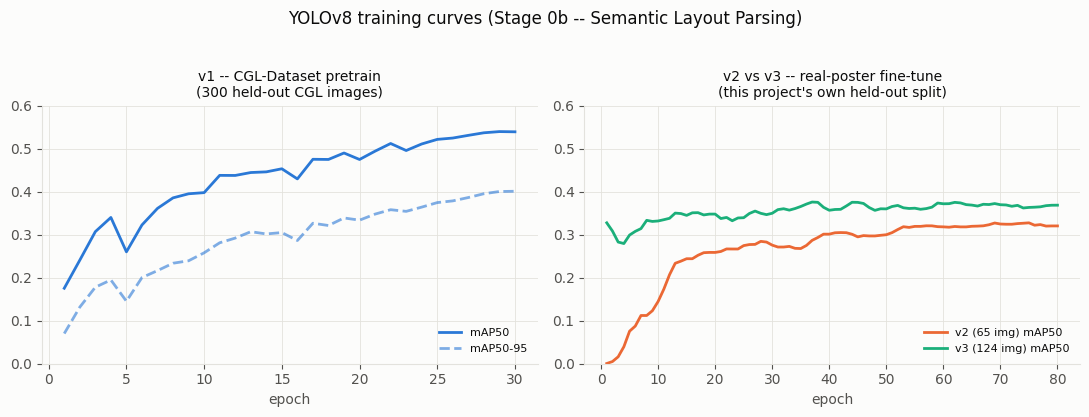

In [2]:
v1 = pd.read_csv(ROOT / "runs/yolo/themesync_layout_yolo/results.csv")
v2 = pd.read_csv(ROOT / "runs/yolo/themesync_master_layout_finetune/results.csv")
v3 = pd.read_csv(ROOT / "runs/yolo/themesync_master_layout_finetune_v3/results.csv")
v1.columns = [c.strip() for c in v1.columns]
v2.columns = [c.strip() for c in v2.columns]
v3.columns = [c.strip() for c in v3.columns]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(v1["epoch"], v1["metrics/mAP50(B)"], color=SERIES_1, linewidth=2, label="mAP50")
axes[0].plot(v1["epoch"], v1["metrics/mAP50-95(B)"], color=SERIES_1, linewidth=2,
             linestyle="--", alpha=0.6, label="mAP50-95")
axes[0].set_title("v1 -- CGL-Dataset pretrain\n(300 held-out CGL images)", fontsize=10)

for df, label, color in [(v2, "v2 (65 img)", SERIES_2), (v3, "v3 (124 img)", SERIES_3)]:
    axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], color=color, linewidth=2, label=f"{label} mAP50")
axes[1].set_title("v2 vs v3 -- real-poster fine-tune\n(this project's own held-out split)", fontsize=10)

for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylim(0, 0.6)
    ax.legend(frameon=False, fontsize=8, loc="lower right")

fig.suptitle("YOLOv8 training curves (Stage 0b -- Semantic Layout Parsing)", y=1.03)
fig.tight_layout()
plt.show()


In [3]:
summary = pd.DataFrame([
    {
        "model": "v1 (CGL pretrain)",
        "val_set": "300 CGL held-out images / 1448 instances",
        "precision": v1["metrics/precision(B)"].iloc[-1],
        "recall": v1["metrics/recall(B)"].iloc[-1],
        "mAP50": v1["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v1["metrics/mAP50-95(B)"].iloc[-1],
    },
    {
        "model": "v2 (65-image real-poster fine-tune)",
        "val_set": "15 held-out real posters",
        "precision": v2["metrics/precision(B)"].iloc[-1],
        "recall": v2["metrics/recall(B)"].iloc[-1],
        "mAP50": v2["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v2["metrics/mAP50-95(B)"].iloc[-1],
    },
    {
        "model": "v3 (124-image real-poster fine-tune)",
        "val_set": "25 held-out real posters",
        "precision": v3["metrics/precision(B)"].iloc[-1],
        "recall": v3["metrics/recall(B)"].iloc[-1],
        "mAP50": v3["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v3["metrics/mAP50-95(B)"].iloc[-1],
    },
]).set_index("model")
summary.round(3)


,val_set,precision,recall,mAP50,mAP50-95
model,,,,,
v1 (CGL pretrain),300 CGL held-out images / 1448 instances,0.580,0.478,0.539,0.401
v2 (65-image real-poster fine-tune),15 held-out real posters,0.627,0.304,0.320,0.183
v3 (124-image real-poster fine-tune),25 held-out real posters,0.459,0.349,0.368,0.212


### A real data-quality catch, before v3 existed

Checking the newly-uploaded 124-image export before training on it found two
real problems, confirmed with an actual test run rather than assumed: (1)
~23% of the images were being silently dropped during training because their
label files mixed plain bounding-box rows with polygon rows -- Ultralytics
discards the whole file rather than partially using it; (2) the class index
order had shifted between exports (alphabetized in the new one), which would
have silently scrambled what v2's checkpoint had already learned if fine-tuned
on as-is. Both fixed (polygons converted to their enclosing boxes, indices
remapped) and re-verified (0 corrupt files) before the retrain below ran. Full
detail: `notes/gnn_fixes_and_methodology_notes.md` Section 3.12.


### Per-class breakdown: v2 vs v3

Not in `results.csv` (Ultralytics only logs aggregate metrics there) -- pulled
from the console output captured in `notes/gnn_fixes_and_methodology_notes.md`
Sections 3.7 (v2) and 3.12 (v3). **`underlay` is still weak** (44 validation
instances now, up from 17 -- better, not yet enough to learn well);
**`embellishment` stayed flat** despite the batch nearly doubling (consistent
with the group's decision not to prioritize hunting for these); `logo` and
`text` -- the two structurally important classes -- both improved meaningfully.


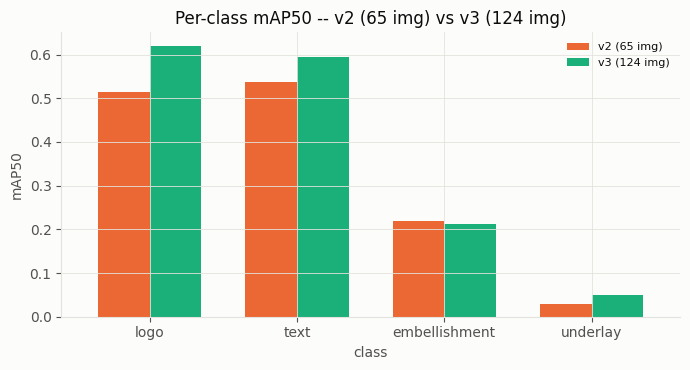

,v2_mAP50,v3_mAP50
class,,
logo,0.5150,0.6200
text,0.5380,0.5950
embellishment,0.2180,0.2130
underlay,0.0288,0.0499


In [4]:
per_class = pd.DataFrame([
    {"class": "logo",          "v2_mAP50": 0.515,  "v3_mAP50": 0.620},
    {"class": "text",          "v2_mAP50": 0.538,  "v3_mAP50": 0.595},
    {"class": "embellishment", "v2_mAP50": 0.218,  "v3_mAP50": 0.213},
    {"class": "underlay",      "v2_mAP50": 0.0288, "v3_mAP50": 0.0499},
]).set_index("class")

ax = per_class.plot(kind="bar", color=[SERIES_2, SERIES_3], figsize=(7, 3.8), width=0.7)
ax.set_ylabel("mAP50")
ax.set_title("Per-class mAP50 -- v2 (65 img) vs v3 (124 img)")
ax.set_xticklabels(per_class.index, rotation=0)
ax.legend(["v2 (65 img)", "v3 (124 img)"], frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

per_class


### Real-domain generalization check (v1 -> v2 -> v3, same 3 unseen posters)

Top detection confidence, and the number of detections usable at conf >= 0.25,
on 3 CSPC posters that were **never** in the annotation batch: a clean test of
whether fine-tuning closed the CGL-to-real-poster domain gap rather than
memorizing training examples. (`YOUR_TEMPLATE2.jpg`, YUGTO 2026, is left out on
purpose: it *was* one of the annotated training images.)

Re-measured 2026-09-28 with `src/evaluation/yolo_domain_gap_check.py`. The v2
values match the earlier measurement (0.74 / 0.73 / 0.69). The v1 values replace
hand-typed ones (0.20 / 0.46 / 0.31) that previously sat in this cell and didn't
match any saved measurement; the re-measured v1 La Serata value (0.035) matches
the original v1 log in notes §3.5.

**How to read v2 vs v3 here:** v3 is more confident on all three posters, but
finds fewer usable detections on two of them (La Serata 16 -> 10, TAN-AW 13 ->
9; LODT 8 -> 11). These posters have no hand-drawn ground truth, so this check
can't tell whether the drop means fewer false positives or more misses. It
shows the domain gap *stays closed*; accuracy comes from the held-out mAP table
above (v3 0.370 vs v2 0.320).

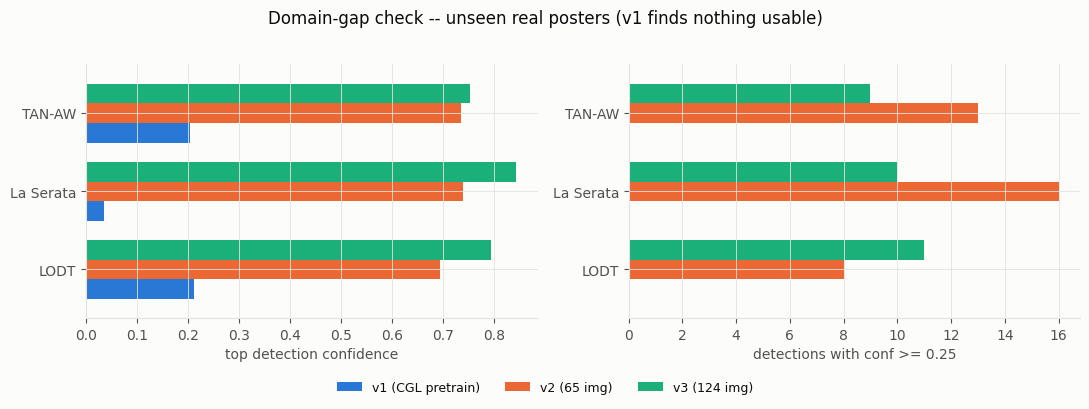

top_conf               usable_detections            
model           v1     v2     v3                v1    v2    v3
poster                                                        
LODT         0.211  0.694  0.793               0.0   8.0  11.0
La Serata    0.035  0.740  0.843               0.0  16.0  10.0
TAN-AW       0.204  0.735  0.753               0.0  13.0   9.0

In [5]:
with open(ROOT / "results/yolo_domain_gap_check.json") as f:
    gap = json.load(f)

gap_rows = []
for version, per_poster in gap["results"].items():
    for poster, m in per_poster.items():
        gap_rows.append({"poster": poster, "model": version,
                         "top_conf": m["top_conf"], "usable_detections": m["n_ge_025"]})
gap_df = pd.DataFrame(gap_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, label in [(axes[0], "top_conf", "top detection confidence"),
                          (axes[1], "usable_detections", "detections with conf >= 0.25")]:
    gap_df.pivot(index="poster", columns="model", values=metric)[["v1", "v2", "v3"]].plot(
        kind="barh", ax=ax, color=[SERIES_1, SERIES_2, SERIES_3], width=0.75)
    ax.set_xlabel(label)
    ax.set_ylabel("")
    ax.get_legend().remove()
fig.legend(["v1 (CGL pretrain)", "v2 (65 img)", "v3 (124 img)"], loc="lower center",
           ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Domain-gap check -- unseen real posters (v1 finds nothing usable)", y=1.02)
fig.tight_layout()
plt.show()

gap_df.pivot(index="poster", columns="model", values=["top_conf", "usable_detections"])

## Phase 3 -- GNN-Guided vs. Baseline Layout Quality

Both Phase 3 runs below were re-run on 2026-09-28 against the current system:
the event-ID format (§3.15), the vertical-balance constraint (§3.16), and the
fix that makes the candidate explorer use each format's own canvas (§3.18).
The previous `experiment_log.json` dated from 2026-08-27, before the penalty
fixes in §3.1-3.3, and its ID half had been scored on a 1200x900 certificate
canvas, so its "GNN better on average" reading no longer applies.

In [6]:
with open(ROOT / "results/experiment_log.json") as f:
    exp = json.load(f)

rows = []
for domain, dd in exp["results"].items():
    for method, trials in [("GNN-guided", dd["gnn_trials"]), ("Baseline", dd["base_trials"])]:
        for t in trials:
            rows.append({
                "format": dd["domain_label"], "method": method,
                "C_total": t["C_total"], "P_align": t["P_align"], "P_space": t["P_space"],
                "P_legibility": t["P_legibility"], "mean_iou": t["mean_iou"],
                "latency_ms": t["latency_total"],
            })
trials_df = pd.DataFrame(rows)

penalties = (trials_df.groupby(["format", "method"])
             [["C_total", "P_align", "P_space", "P_legibility", "mean_iou"]]
             .agg(["mean", "std"]).round(4))
penalties

C_total      P_align      P_space       \
                                         mean  std    mean  std    mean  std   
format                     method                                              
Academic Certificate (4:3) Baseline    1.1876  0.0  0.0000  0.0  0.0626  0.0   
                           GNN-guided  1.2029  0.0  0.0077  0.0  0.0626  0.0   
Event ID (A6, 1:1.414)     Baseline    1.2834  0.0  0.0000  0.0  0.1584  0.0   
                           GNN-guided  1.3012  0.0  0.0089  0.0  0.1584  0.0   

                                      P_legibility      mean_iou       
                                              mean  std     mean  std  
format                     method                                      
Academic Certificate (4:3) Baseline           0.75  0.0   0.0000  0.0  
                           GNN-guided         0.75  0.0   0.1682  0.0  
Event ID (A6, 1:1.414)     Baseline           0.75  0.0   0.0000  0.0  
                           GNN-guided         0.75  0.0   0.0000  0.0

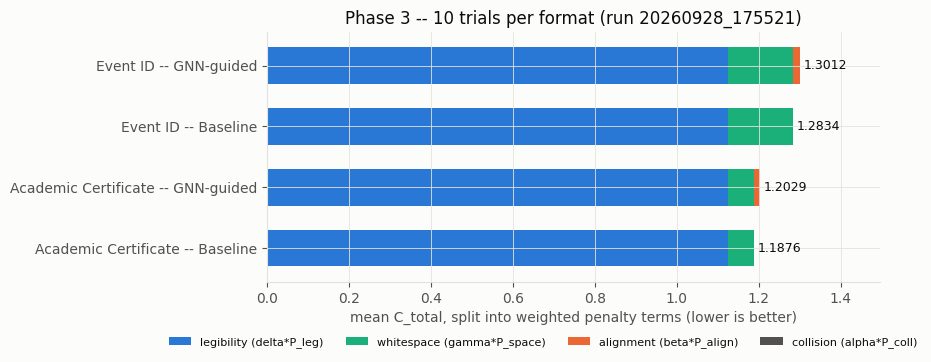

,legibility (delta*P_leg),whitespace (gamma*P_space),alignment (beta*P_align),collision (alpha*P_coll),C_total
Academic Certificate -- Baseline,1.125,0.0626,0.0000,0.0,1.1876
Academic Certificate -- GNN-guided,1.125,0.0626,0.0154,0.0,1.2029
Event ID -- Baseline,1.125,0.1584,0.0000,0.0,1.2834
Event ID -- GNN-guided,1.125,0.1584,0.0178,0.0,1.3012


In [7]:
import sys
sys.path.insert(0, str(ROOT / "src" / "solvers"))
from optimization_engine import HeuristicEvaluator

# Split each mean C_total into its weighted Formula 3.11 terms, using the
# evaluator's own weights, so a 1.20-vs-1.19 difference isn't lost in bars
# that start at zero. Collision isn't logged per trial; it is the remainder
# (0 in every run here -- the solver guarantees no overlap).
w = HeuristicEvaluator()
means = trials_df.groupby(["format", "method"])[["C_total", "P_align", "P_space", "P_legibility"]].mean()
parts = pd.DataFrame({
    "legibility (delta*P_leg)": w.delta * means["P_legibility"],
    "whitespace (gamma*P_space)": w.gamma * means["P_space"],
    "alignment (beta*P_align)": w.beta * means["P_align"],
})
parts["collision (alpha*P_coll)"] = (means["C_total"] - parts.sum(axis=1)).clip(lower=0).round(6)

parts.index = [f"{fmt.split(' (')[0]} -- {method}" for fmt, method in parts.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
parts.plot(kind="barh", stacked=True, ax=ax,
           color=[SERIES_1, SERIES_3, SERIES_2, TEXT_SECONDARY], width=0.6)
for i, total in enumerate(means["C_total"]):
    ax.text(total + 0.01, i, f"{total:.4f}", va="center", fontsize=9, color=TEXT_PRIMARY)
ax.set_xlabel("mean C_total, split into weighted penalty terms (lower is better)")
ax.set_ylabel("")
ax.set_xlim(0, means["C_total"].max() * 1.15)
ax.set_title(f"Phase 3 -- {exp['config']['trials']} trials per format (run {exp['run_id']})")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.18), ncol=4)
plt.tight_layout()
plt.show()

parts.assign(C_total=means["C_total"].values).round(4)

**Reading this run (10 trials per format):**

- **Baseline wins on both formats, narrowly.** Certificate C_total is 1.2029
  (GNN) vs 1.1876 (baseline); event ID is 1.3012 vs 1.2834. The *whole*
  difference is P_align: the GNN places nodes off the structural grid on the
  x axis. P_space and P_legibility are identical for both methods.
- **C_total has zero variance across trials** (std 0.0). With a fixed payload,
  fixed weights and no random seed, the pipeline is deterministic; the trials
  only measure latency. So this is a stable result, not noise. It also means
  "more trials" won't change the verdict; only a different payload or poster
  will.
- **The fitness function can't see vertical placement.** In this synthetic
  mode (no poster, so no saliency map) every penalty is invariant to moving
  the layout up or down: P_align measures x only, P_whitespace is a global
  area ratio (Formula 3.14), collision is zero, and legibility is flat. Moving
  the whole stack from top-heavy to vertically balanced (§3.16) left C_total
  unchanged. This is a concrete reason the manuscript needs Phase 4's human
  MOS on top of the math (pp. 58, 62).
- **`mean_iou` is a diagnostic, not a manuscript metric.** It is the overlap
  between the GNN's predicted boxes and the solver's final boxes. Chapter 3
  confines IoU to Phase 1 extraction and explicitly excludes generated
  layouts (pp. 55-56). The GNN predicts y positions that ignore the reading
  order (e.g. the ID title above the logo row, the header near the bottom), so
  the solver's strong stacking rule overrides them. The ID's 0.0 reflects the
  balance rule then shifting the whole stack; the old solver's 0.128 was mostly
  coincidental overlap (§3.16).

In [8]:
with open(ROOT / "results/evaluation_results.json") as f:
    ev = json.load(f)

fixed_rows = []
for method, trials in [("GNN-guided", ev["gnn_guided"]), ("Baseline", ev["baseline"])]:
    for t in trials:
        fixed_rows.append({
            "method": method,
            "mean_iou": t["mean_iou"],
            "C_total": t["heuristic_fitness"]["C_total"],
            "constraint_f1": t["constraint_f1"]["f1"],
        })
fixed_df = pd.DataFrame(fixed_rows)
fixed_df.groupby("method").mean(numeric_only=True).round(4)


,mean_iou,C_total,constraint_f1
method,,,
Baseline,0.0000,1.1876,1.0
GNN-guided,0.1682,1.2029,1.0


**This is the exact comparison `tests/test_certificate_pipeline.py`'s
`test_gnn_improves_over_baseline` runs.** It agrees with the 10-trial battery
above: GNN C_total 1.2029 vs baseline 1.1876, a gap coming entirely from
P_align. That test only prints the direction and always passes by design
(the result is a thesis observation, not a correctness check).

**Worth raising with the adviser as an honest result:** on the synthetic
templates, GNN guidance does not improve the heuristic fitness. Its
horizontal placements cost alignment, and its vertical placements are
overridden by the constraint solver. This matches the limitation already
noted in §1.4 (the GNN has no reading-order awareness). It is also
consistent with the training-data gap in the adviser checklist, section B
(the GNN never saw real per-node features).

## Phase 4 -- Expert Aesthetic Validation (MOS)

**No real data yet.** `src/evaluation/mos_collector.py` is built and, as of
2026-09-26, matches the manuscript's instrument (pp. 57-58): the 3 named
parameters (Visual Hierarchy Preservation, Brand and Typographic
Consistency, Constraint and Whitespace Harmony), Table 2's rating scale shown
to the evaluator, and layouts presented in randomized order. But
`results/mos_results.json` doesn't exist yet: no domain expert has rated any
output. This section is intentionally left as a placeholder rather than
filled with synthetic numbers. Re-run this notebook once a real MOS session
has been collected and this cell will pick the data up automatically.


In [9]:
mos_path = ROOT / "results" / "mos_results.json"
if mos_path.exists():
    with open(mos_path) as f:
        mos = json.load(f)
    print(f"{len(mos.get('evaluations', []))} real MOS evaluation(s) found -- rerun analysis below.")
else:
    print("No results/mos_results.json yet -- Phase 4 has zero real evaluator data as of this run.")


No results/mos_results.json yet -- Phase 4 has zero real evaluator data as of this run.
